In [25]:
import torch
import matplotlib.pyplot as plt



def get_brownian_bridge(
    sigma,
    eps,
    x_pairs: torch.Tensor,
    t_pairs: torch.Tensor,
    direction: str,
):
  
    z0, z1 = x_pairs[:, 0], x_pairs[:, 1]
    t1, t2 = t_pairs[:, 0], t_pairs[:, 1]
    t1 = t1.unsqueeze(1)
    t2 = t2.unsqueeze(1)

    t = torch.rand((z0.shape[0], 1))
    t = t1 + (t2 - t1) * ((1 - 2 * eps) * t + eps)
    s = (t - t1) / (t2 - t1)
    z_t = (1 - s) * z0 + s * z1
    z = torch.randn_like(z_t)
    z_t = z_t + sigma * torch.sqrt(s * (1 - s)) * z

    if direction == "forward":
        target = (z1 - z0) - sigma * torch.sqrt(s / (1 - s)) * z
    elif direction == "backward":
        target = -(z1 - z0) - sigma * torch.sqrt((1 - s) / s) * z
    else:
        raise ValueError("Direction must be 'forward' or 'backward'.")

    return z_t, t, target



In [8]:
# Générer 3000 points pour chaque gaussienne (2D)
n_points = 3000

# Première gaussienne : moyenne (0,0), std 1
gauss1 = torch.randn(n_points, 2)

# Deuxième gaussienne : moyenne (6,6), std 1
gauss2 = torch.randn(n_points, 2) + torch.tensor([6.0, 6.0])

# Empiler les deux ensembles
data = torch.stack([gauss1, gauss2], dim=1)  # (6000, 2)

print(data.shape)  # (6000, 2)


torch.Size([3000, 2, 2])


In [14]:
t_pairs = torch.tensor([[0.0, 0.5]]).repeat(n_points, 1)

In [15]:
t_pairs

tensor([[0.0000, 0.5000],
        [0.0000, 0.5000],
        [0.0000, 0.5000],
        ...,
        [0.0000, 0.5000],
        [0.0000, 0.5000],
        [0.0000, 0.5000]])

In [37]:
result = get_brownian_bridge(1e-4,1e-3,data,t_pairs,"backward")

In [38]:
result[0].shape

torch.Size([3000, 2])

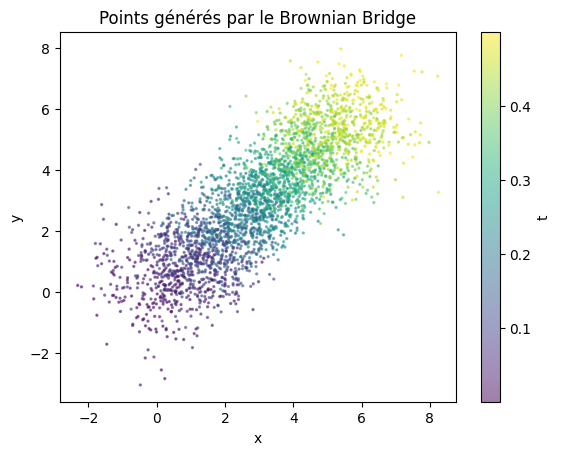

In [39]:
sc = plt.scatter(result[0][:, 0], result[0][:, 1], c=result[1].squeeze(), cmap='viridis', alpha=0.5, s=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Points générés par le Brownian Bridge")
plt.colorbar(sc, label="t")


In [34]:
import torch
@torch.no_grad()
def inference_sample_sde(
    zstart: torch.Tensor,
    t_pairs: torch.Tensor,
    device: str,
    net_dict,
    direction_tosample: str,
    N: int = 1000,
    sig: float = 1.0,

):
    assert direction_tosample in ["forward", "backward"]
    t_max = t_pairs[:,1]
    t_min = t_pairs[:,0]

    full_traj_tmax = t_pairs.cpu().max()
    full_traj_tmin = t_pairs.cpu().min()

    sign = 1

    time_deltas = t_max - t_min
    tensor_of_proportions_of_total = time_deltas / (full_traj_tmax - full_traj_tmin)

    N_step = (N * tensor_of_proportions_of_total).int()
    
    ts = []
    dt_list = []

    for num_bridge in range(len(t_pairs)):
        bridge_ts = torch.linspace(t_min[num_bridge], t_max[num_bridge], N_step[num_bridge])
        ts.append(bridge_ts[:-1])
        # Calculer dt pour ce bridge
        bridge_dt = torch.diff(bridge_ts)
        dt_list.append(bridge_dt)

    score = net_dict[direction_tosample].eval()

    z = zstart.detach().clone()
    ts = torch.cat(ts)
    dt = torch.cat(dt_list)

    traj = [z.detach().clone()]
    t_list = [ts[0]]

    if direction_tosample == "backward":
        ts = torch.flip(ts, [0])
        dt = torch.flip(dt, [0])
        sign = -1

    batchsize = z.shape[0]

    for i in range(len(ts)):
        t = torch.full((batchsize, 1), float(ts[i]), device=device)

        t_list.append(ts[i] + dt[i] * sign)

        pred = score(z, t)

        z = z + pred * dt[i] + sig * torch.randn_like(z) * torch.sqrt(dt[i])

        traj.append(z.detach().clone())
    
    return traj, t_list

In [41]:
import torch
@torch.no_grad()
def inference_sample_sde(
    zstart: torch.Tensor,
    t_pairs: torch.Tensor,
    device: str,
    net_dict,
    direction_tosample: str,
    N: int = 1000,
    sig: float = 1.0,

):
    assert direction_tosample in ["forward", "backward"]
    t_max = t_pairs[:,1]
    t_min = t_pairs[:,0]

    full_traj_tmax = t_pairs.cpu().max()
    full_traj_tmin = t_pairs.cpu().min()

    sign = 1

    time_deltas = t_max - t_min
    tensor_of_proportions_of_total = time_deltas / (full_traj_tmax - full_traj_tmin)

    N_step = (N * tensor_of_proportions_of_total).int()
    
    ts = []
    dt_list = []

    for num_bridge in range(len(t_pairs)):
        bridge_ts = torch.linspace(t_min[num_bridge], t_max[num_bridge], N_step[num_bridge])
        ts.append(bridge_ts[:-1])
        # Calculer dt pour ce bridge
        bridge_dt = torch.diff(bridge_ts)
        dt_list.append(bridge_dt)

    score = net_dict[direction_tosample].eval()

    z = zstart.detach().clone()
    ts = torch.cat(ts)
    dt = torch.cat(dt_list)

    traj = [z.detach().clone()]
    t_list = [ts[0]]

    print(ts)

    if direction_tosample == "backward":
        ts = torch.flip(ts, [0])
        dt = torch.flip(dt, [0])
        sign = -1

    batchsize = z.shape[0]

    for i in range(len(ts)):
        t = torch.full((batchsize, 1), float(ts[i]), device=device)

        t_list.append(ts[i] + dt[i] * sign)

        pred = score(z, t)

        z = z + pred * dt[i] + sig * torch.randn_like(z) * torch.sqrt(dt[i])

        traj.append(z.detach().clone())
    
    return traj, t_list

In [42]:
import torch 

batchsize = 3
dim = 2

# Création de zstart : tenseur aléatoire de taille (batchsize, dim)
zstart = torch.randn(batchsize, dim)

# Création de t_pairs : couples (t_min, t_max)
t_pairs = torch.tensor([[0.0, 1.0], [1.0, 3.0], [3.0, 6.0]])

import torch.nn as nn

class SimpleNet(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(dim + 1, 32),
            nn.ReLU(),
            nn.Linear(32, dim)
        )

    def forward(self, z, t):
        # z: (batchsize, dim), t: (batchsize, 1)
        x = torch.cat([z, t], dim=1)
        return self.fc(x)


device = "cuda"
net = SimpleNet(dim)
net = net.to(device)
net_dict = {"forward": net}

direction_tosample = "forward"
sig = 1.0

zstart = zstart.to(device)
t_pairs = t_pairs.to(device)


In [43]:
inference_sample_sde(
    zstart=zstart,
    t_pairs=t_pairs,
    device=device,
    net_dict=net_dict,
    direction_tosample=direction_tosample,
    N=1000,
    sig=sig
)

tensor([0.0000, 0.0061, 0.0121, 0.0182, 0.0242, 0.0303, 0.0364, 0.0424, 0.0485,
        0.0545, 0.0606, 0.0667, 0.0727, 0.0788, 0.0848, 0.0909, 0.0970, 0.1030,
        0.1091, 0.1152, 0.1212, 0.1273, 0.1333, 0.1394, 0.1455, 0.1515, 0.1576,
        0.1636, 0.1697, 0.1758, 0.1818, 0.1879, 0.1939, 0.2000, 0.2061, 0.2121,
        0.2182, 0.2242, 0.2303, 0.2364, 0.2424, 0.2485, 0.2545, 0.2606, 0.2667,
        0.2727, 0.2788, 0.2848, 0.2909, 0.2970, 0.3030, 0.3091, 0.3152, 0.3212,
        0.3273, 0.3333, 0.3394, 0.3455, 0.3515, 0.3576, 0.3636, 0.3697, 0.3758,
        0.3818, 0.3879, 0.3939, 0.4000, 0.4061, 0.4121, 0.4182, 0.4242, 0.4303,
        0.4364, 0.4424, 0.4485, 0.4545, 0.4606, 0.4667, 0.4727, 0.4788, 0.4848,
        0.4909, 0.4970, 0.5030, 0.5091, 0.5152, 0.5212, 0.5273, 0.5333, 0.5394,
        0.5455, 0.5515, 0.5576, 0.5636, 0.5697, 0.5758, 0.5818, 0.5879, 0.5939,
        0.6000, 0.6061, 0.6121, 0.6182, 0.6242, 0.6303, 0.6364, 0.6424, 0.6485,
        0.6545, 0.6606, 0.6667, 0.6727, 

([tensor([[-1.2734,  1.7897],
          [-0.7515, -2.1214],
          [ 1.5149,  0.7983]], device='cuda:0'),
  tensor([[-1.2035,  1.7753],
          [-0.7046, -2.1465],
          [ 1.4637,  0.9046]], device='cuda:0'),
  tensor([[-1.1967,  1.7946],
          [-0.6834, -2.0070],
          [ 1.2949,  0.9742]], device='cuda:0'),
  tensor([[-1.2212,  1.9531],
          [-0.7161, -1.9442],
          [ 1.3732,  1.0481]], device='cuda:0'),
  tensor([[-1.2276,  2.0033],
          [-0.7889, -1.9447],
          [ 1.3674,  1.0017]], device='cuda:0'),
  tensor([[-1.2457,  1.9754],
          [-0.7679, -1.9395],
          [ 1.3447,  1.0751]], device='cuda:0'),
  tensor([[-1.2488,  2.0763],
          [-0.7497, -1.9103],
          [ 1.4605,  1.1515]], device='cuda:0'),
  tensor([[-1.2201,  2.1758],
          [-0.7196, -1.8083],
          [ 1.5063,  1.0824]], device='cuda:0'),
  tensor([[-1.3237,  2.2243],
          [-0.6560, -1.6926],
          [ 1.5577,  0.9348]], device='cuda:0'),
  tensor([[-1.2047,

In [ ]:
@torch.no_grad()
def inference_sample_sde(
    zstart: torch.Tensor,
    t_pairs: torch.Tensor,
    device: str,
    net_dict,
    direction_tosample: str,
    N: int = 1000,
    sig: float = 1.0,

):
    assert direction_tosample in ["forward", "backward"]


    full_traj_tmax = t_pairs.cpu().max()
    full_traj_tmin = t_pairs.cpu().min()

    sign = 1.

    dt_step = 3 / N

    ts = torch.arange(full_traj_tmin, full_traj_tmax, step = dt_step)
    


    score = net_dict[direction_tosample].eval()

    z = zstart.detach().clone()


    traj = [z.detach().clone()]
    t_list = [ts[0]]

    if direction_tosample == "backward":
        sign = -1
        ts = torch.arange(full_traj_tmax, full_traj_tmin, step = -dt_step)

    dt =  torch.tensor(3./ N)

    batchsize = z.shape[0]

    for i in range(len(ts)):
        t = torch.full((batchsize, 1), float(ts[i]), device=device)

        t_list.append(ts[i] + dt_step * sign)

        pred = score(z, t)

        z = z + pred * dt + sig * torch.randn_like(z) * torch.sqrt(dt)

        traj.append(z.detach().clone())
    
    return traj, t_list

Sauvegarde sample sde

In [ ]:
@torch.no_grad()
def sample_sde(
    zstart: torch.Tensor,
    t_pairs: Tensor,
    net_dict,
    direction_tosample: str,
    N: int,
    sig: float,
    device: str,
    full_traj_tmax: float,
    full_traj_tmin: float,
):
    assert direction_tosample in ["forward", "backward"]

    t_min = t_pairs[:, 0]
    t_max = t_pairs[:, 1]

    time_deltas = t_max - t_min
    tensor_of_proportions_of_total = time_deltas / (full_traj_tmax - full_traj_tmin)

    # create the linspace for each time delta proportionally to the total time of the full trajectory
    proportions_of_total = {
        one_time_delta: one_time_delta / (full_traj_tmax - full_traj_tmin)
        for one_time_delta in torch.unique(time_deltas)
    }
    #print(f"DEBUG proportions_of_total: {proportions_of_total}")
    steps = {
    one_time_delta: torch.linspace(
        0, 1, int(torch.round(N * proportions_of_total[one_time_delta]).item()), device=device
    )
    for one_time_delta in proportions_of_total
}
    max_nb_steps = max(len(s) for s in steps.values())

    # expend t_min and t_max to create the linspace
    t_min_exp = t_min.unsqueeze(1)  # shape [6000, 1]
    t_max_exp = t_max.unsqueeze(1)  # shape [6000, 1]

    # Interpolation linéaire entre t_min et t_max
    ts = torch.full(
        (len(t_min), max_nb_steps), float("nan"), dtype=torch.float, device=device
    )  # shape [6000, N]
    for one_time_delta in steps:
        this_time_delta_indices = time_deltas == one_time_delta
        this_time_delta_t_min_exp = t_min_exp[this_time_delta_indices]
        this_time_delta_t_max_exp = t_max_exp[this_time_delta_indices]
        this_time_delta_ts = (
            this_time_delta_t_min_exp
            + (this_time_delta_t_max_exp - this_time_delta_t_min_exp)
            * steps[one_time_delta]
        )
        # Pad this_time_delta_ts with NaNs to have shape [num_samples, max_nb_steps]
        pad_size = max_nb_steps - this_time_delta_ts.shape[1]
        if pad_size > 0:
            nan_pad = torch.full((this_time_delta_ts.shape[0], pad_size), float("nan"), device=device)
            this_time_delta_ts = torch.cat([this_time_delta_ts, nan_pad], dim=1)

        ts[this_time_delta_indices] = this_time_delta_ts



    dt = 1.0 / (N * tensor_of_proportions_of_total)
    dt = dt.unsqueeze(1)

    if direction_tosample == "backward":
        ts = ts.flip(dims=[1])
        dt = dt.flip(dims=[1])

    z = zstart.detach().clone()
    score = net_dict[direction_tosample].eval()

    for i in range(max_nb_steps):  # TODO: clean the [mask]s
        mask = ~torch.isnan(ts[:, i])  # mask to filter out NaNs
        t = ts[mask, i].unsqueeze(
            1
        )  # shape [batchsize, 1], chaque sample a son propre t
        pred = score(
            z[mask], t
        )  # assume score accepte [batchsize, D] et [batchsize, 1]
        z[mask] = (
            z[mask]
            + pred * dt[mask]
            + sig * torch.randn_like(z[mask]) * torch.sqrt(dt[mask])
        )

    return z